In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

# Loading dataset

In [2]:
# !pip install ucimlrepo        # as I am using local env and using uv not pip so commenting this line

from ucimlrepo import fetch_ucirepo

# fetch dataset
concrete_compressive_strength = fetch_ucirepo(id=165)

# metadata
print(concrete_compressive_strength.metadata)

# variable information
print(concrete_compressive_strength.variables)

# data (as pandas dataframes)
df = concrete_compressive_strength.data.features
df['target'] = concrete_compressive_strength.data.targets

{'uci_id': 165, 'name': 'Concrete Compressive Strength', 'repository_url': 'https://archive.ics.uci.edu/dataset/165/concrete+compressive+strength', 'data_url': 'https://archive.ics.uci.edu/static/public/165/data.csv', 'abstract': 'Concrete is the most important material in civil engineering. The concrete compressive strength is a highly nonlinear function of age and ingredients. ', 'area': 'Physics and Chemistry', 'tasks': ['Regression'], 'characteristics': ['Multivariate'], 'num_instances': 1030, 'num_features': 8, 'feature_types': ['Real'], 'demographics': [], 'target_col': ['Concrete compressive strength'], 'index_col': None, 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 1998, 'last_updated': 'Sun Feb 11 2024', 'dataset_doi': '10.24432/C5PK67', 'creators': ['I-Cheng Yeh'], 'intro_paper': {'ID': 383, 'type': 'NATIVE', 'title': 'Modeling of strength of high-performance concrete using artificial neural networks', 'authors': 'I. Yeh', 'venue': 'C

In [3]:
df.head(5)

,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age,target
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30


# removing duplicates

In [4]:
# counting duplicates
print(f'number of duplicates: {df.duplicated(subset=df.columns[:-1]).sum()}')

number of duplicates: 38


In [5]:
df = df.drop_duplicates(subset=df.columns[:-1])
df.head(5)

,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age,target
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30


# null values

In [6]:
# checking for null values
df.isnull().sum()

Cement                0
Blast Furnace Slag    0
Fly Ash               0
Water                 0
Superplasticizer      0
Coarse Aggregate      0
Fine Aggregate        0
Age                   0
target                0
dtype: int64

# spliting dataset

In [7]:
from sklearn.model_selection import train_test_split

X, y = df[df.columns[:-1]], df[df.columns[-1]]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
X_test, X_val, y_test, y_val = train_test_split(X_test, y_test, train_size=0.5, random_state=42)
del df, X, y

# Adaboost regressor implementation

In [8]:
import numpy as np
from sklearn.tree import DecisionTreeRegressor

class ImplAdaBoostRegressor:
    def __init__(self, n_estimators: int, learning_rate: float = 1.0):
        self.n_estimators = n_estimators
        self.lr = learning_rate
        self.estimators = []

    def fit(self, X: np.ndarray, y: np.ndarray):
        N = y.size
        weights = np.full(N, 1 / N)

        for step in range(self.n_estimators):
            weak_regressor = DecisionTreeRegressor(max_depth=1)
            weak_regressor.fit(X, y, sample_weight=weights)

            err = np.abs(weak_regressor.predict(X) - y)
            max_err = np.max(err)
            if max_err == 0:
                break
            normalized_err = err / max_err
            weighted_err = np.dot(normalized_err, weights)
            weighted_err = np.clip(weighted_err, 1e-10, 1 - 1e-10)

            if weighted_err >= 0.5:
                print(f"Stopping early at step {step}")
                break

            B = weighted_err / (1 - weighted_err)
            alpha = self.lr * np.log(1 / B)

            weights *= np.power(B, 1 - normalized_err)
            weights /= np.sum(weights)

            self.estimators.append((alpha, weak_regressor))

    def predict(self, X: np.ndarray) -> np.ndarray:
        if not self.estimators:
            raise ValueError("Model not fitted yet.")
        a_sum = sum(a for a, _ in self.estimators)
        y_sum = sum(a * model.predict(X) for a, model in self.estimators)
        return y_sum / a_sum


# best hyperparameter

In [9]:
from sklearn.metrics import r2_score

M_list = [5, 10, 20, 40, 60, 80, 100, 150, 200, 500, 1000, 5000, 10000]
impl_r2_scores = dict()
for m in M_list:
    model = ImplAdaBoostRegressor(n_estimators=m)
    model.fit(X=X_train, y=y_train)
    y_pred = model.predict(X_val)
    r2 = r2_score(y_pred=y_pred, y_true=y_val)
    impl_r2_scores[m] = r2

Stopping early at step 101
Stopping early at step 101
Stopping early at step 101
Stopping early at step 101
Stopping early at step 101
Stopping early at step 101


# Plot r2 score vs M

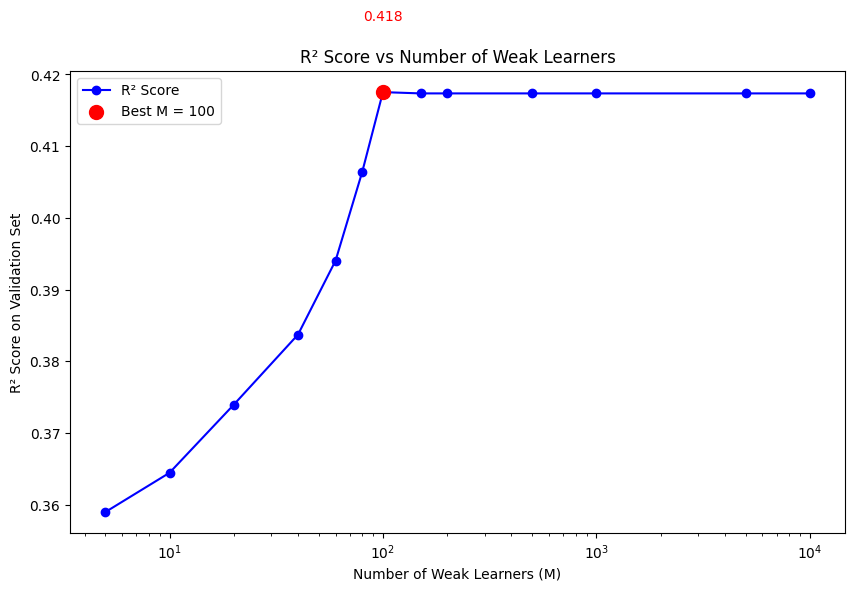

In [10]:
import matplotlib.pyplot as plt

M_values = list(impl_r2_scores.keys())
r2_scores = list(impl_r2_scores.values())

impl_best_M = max(impl_r2_scores, key=impl_r2_scores.get)
impl_best_r2 = impl_r2_scores[impl_best_M]

plt.figure(figsize=(10,6))
plt.plot(M_values, r2_scores, marker='o', linestyle='-', color='b', label='R² Score')
plt.scatter(impl_best_M, impl_best_r2, color='red', s=100, zorder=5, label=f'Best M = {impl_best_M}')
plt.text(impl_best_M, impl_best_r2 + 0.01, f'{impl_best_r2:.3f}', color='red', ha='center')

plt.xscale('log')
plt.xlabel('Number of Weak Learners (M)')
plt.ylabel('R² Score on Validation Set')
plt.title('R² Score vs Number of Weak Learners')
plt.legend()
plt.show()


# implemented model test set score

In [11]:
impl_best_model = ImplAdaBoostRegressor(n_estimators=impl_best_M)
impl_best_model.fit(X=X_train, y=y_train)
impl_test_pred = impl_best_model.predict(X_test)

impl_test_r2 = r2_score(y_true=y_test, y_pred=impl_test_pred)
print(f'test set r2 score: {impl_test_r2}')

test set r2 score: 0.450961715041155


# test set scatterplot

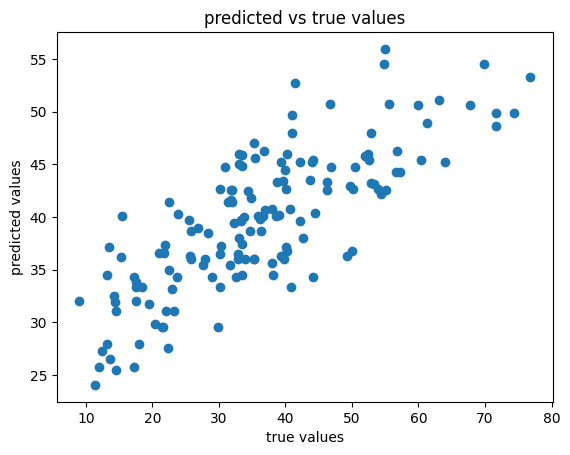

In [12]:
plt.scatter(x=y_test, y=impl_test_pred)
plt.xlabel('true values')
plt.ylabel('predicted values')
plt.title('predicted vs true values')
plt.show()

# sklearn implementation training

In [13]:
from sklearn.ensemble import AdaBoostRegressor
from sklearn.tree import DecisionTreeRegressor

sklearn_r2_scores = dict()

for m in M_list:
    base_learner = DecisionTreeRegressor(max_depth=1)

    model = AdaBoostRegressor(
        estimator=base_learner,
        n_estimators=m,
        learning_rate=1.0,
        loss="linear",
        random_state=42
    )

    model.fit(X_train, y_train)
    y_pred = model.predict(X_val)
    r2 = r2_score(y_val, y_pred)
    sklearn_r2_scores[m] = r2

sk_best_M = max(sklearn_r2_scores, key=sklearn_r2_scores.get)
sk_best_r2 = sklearn_r2_scores[sk_best_M]
print(f'sklearn best M: {sk_best_M}, r2 score: {sk_best_r2}')

sklearn best M: 60, r2 score: 0.515947790133517


# best sklearn model perf on test set

In [14]:
sk_base_learner = DecisionTreeRegressor(max_depth=1)
sk_bset_model = AdaBoostRegressor(
    estimator=base_learner,
    n_estimators=sk_best_M,
    learning_rate=1.0,
    loss="linear",
    random_state=42
)
sk_bset_model.fit(X=X_train, y=y_train)

sk_test_pred = sk_bset_model.predict(X_test)
sk_test_r2 = r2_score(y_true=y_test, y_pred=sk_test_pred)
print(f'sklearn test r2 score: {sk_test_r2}')

sklearn test r2 score: 0.4986591691889597


# scatterplot of sklearn predictions

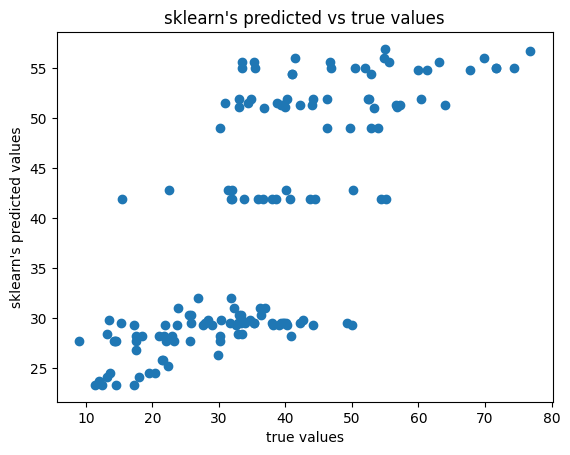

In [15]:
plt.scatter(x=y_test, y=sk_test_pred)
plt.xlabel('true values')
plt.ylabel("sklearn's predicted values")
plt.title("sklearn's predicted vs true values")
plt.show()

# comparision

In [16]:
print('test set performance comparision')
print(f'my implementation best r2: {impl_test_r2} on {impl_best_M} estimators')
print(f'sklearn best r2 {sk_test_r2} on {sk_best_M} estimators')

test set performance comparision
my implementation best r2: 0.450961715041155 on 100 estimators
sklearn best r2 0.4986591691889597 on 60 estimators
